In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
units = pd.read_csv('units_L234.csv').copy()

In [5]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

In [6]:
units_cleaned = clean_dataset(units)

In [7]:
mask_exc = (units_cleaned['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (units_cleaned['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')

In [8]:
E_L23 = units_cleaned[mask_exc & mask_l23].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [9]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size
print(E_L23)

               pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0      864691135275621605     524.797852     223.267166     719.960022   
1      864691135738006641     501.233734     104.152145     960.080017   
2      864691135865195484     495.966309     215.026978     716.640015   
3      864691135754570189     534.967834     225.249084     904.119995   
4      864691135463256477     476.231995     135.114929     804.239990   
...                   ...            ...            ...            ...   
13152  864691135785734340     600.477844     112.385170    1072.319946   
13153  864691135463316893     503.205322      97.771706    1003.919983   
13154  864691135491839207     502.633148      99.905960    1009.440002   
13155  864691135754440909     371.178406      83.137115    1005.440002   
13156  864691135584253304     538.582031      84.805649    1044.839966   

      classification_system            strategy_axon layer  gOSI_data  \
0         excitatory_neuron  axon_part

In [10]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [11]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [12]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [13]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs = all_pairs.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [14]:


def build_dataset(pre_pop, post_pop, synapses, metric=['Euclidean']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1(pre_pop, post_pop, synapses, metric)
    print(len(conn_dist))
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    print(len(pot_dist))

    """conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()"""

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )
    global id_map, all_ids
    all_ids = pd.Index(pd.concat([
    df['pre_pt_root_id'],
    df['post_pt_root_id']
    ]).unique())
    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    # active_ids = pd.Index(pd.concat([
    #     conn_dist['pre_pt_root_id'],
    #     conn_dist['post_pt_root_id']
    # ]).unique())

    # active_ids_index = active_ids.map(id_map).values



    pre_idx = df['pre_pt_root_id'].map(id_map).values
    post_idx = df['post_pt_root_id'].map(id_map).values


    
    features = ['euclidean']
    print(f'metri vaut {metric}')
    if 'Ori_Diff' in metric:
        features.append('ori_diff_polar')

    X = df[features].values
    y = df['label'].values

    return X, y, features, pre_idx, post_idx

In [15]:
path, pre, post = pathways[0]
X, y, features, pre_idx, post_idx = build_dataset(pre, post, synapses, metric=['Euclidean'])

40020
5525520
metri vaut ['Euclidean']


In [16]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_embedding_MLP_no_distance_50_epoch_10_patience_2_hidden_layers_of_32_neurons_Relu_in_between_LR_102_lastrush"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 50
PATIENCE = 10
LR = 1e-3
DIMS = [2,3,4,5]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [17]:
class EmbeddingModel(nn.Module):
    def __init__(self, n_neurons, dim=20, hidden=64):
        super().__init__()

        self.dim = dim
        self.Z = nn.Embedding(n_neurons, dim)
        nn.init.normal_(self.Z.weight, mean=0.0, std=0.1)

        self.mlp = nn.Sequential(
            nn.Linear(2 * dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward_logits(self, pre_idx, post_idx):
        zi = self.Z(pre_idx)
        zj = self.Z(post_idx)

        x = torch.cat([zi, zj], dim=1)

        logits = self.mlp(x).squeeze(1)
        return logits

    def forward(self, pre_idx, post_idx):
        return torch.sigmoid(self.forward_logits(pre_idx, post_idx))

In [18]:
# =========================
# Data
# =========================

_, y, _, pre_idx, post_idx = build_dataset(
    pre, post, synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

pre_idx = pre_idx.to(DEVICE)
post_idx = post_idx.to(DEVICE)
y = y.to(DEVICE)

dataset = TensorDataset(pre_idx, post_idx, y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

40020
5525520
metri vaut ['Euclidean']
n_neurons: 13157
n_pairs: 5525520
positive rate: 0.007242757361382246


In [19]:
# =========================
# Eval
# =========================

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_y = []
    all_preds = []

    with torch.no_grad():
        for pi, pj, yb in loader:

            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(yb)
            all_y.append(yb.cpu().numpy())
            all_preds.append(probs.cpu().numpy())

    all_y = np.concatenate(all_y)
    all_preds = np.concatenate(all_preds)

    auc = roc_auc_score(all_y, all_preds)

    return total_loss / len(loader.dataset), auc


In [20]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [21]:
# import os
dim = 1
# dim = 1  # change selon la dimension qui plante
# bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

# if os.path.exists(bad_path):
#     os.remove(bad_path)
#     print("Deleted:", bad_path)

In [22]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [65]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = EmbeddingModel(n_neurons=n_neurons, dim=dim).to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    #pos_weight = (y == 0).sum() / (y == 1).sum()
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb in train_loader:
            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 2
dim=02 | epoch=000 | train_loss=0.3420 | val_loss=0.0999 | val_auc=0.5554
dim=02 | epoch=001 | train_loss=0.0567 | val_loss=0.0425 | val_auc=0.6472
dim=02 | epoch=002 | train_loss=0.0412 | val_loss=0.0403 | val_auc=0.7332
dim=02 | epoch=003 | train_loss=0.0396 | val_loss=0.0392 | val_auc=0.7833
dim=02 | epoch=004 | train_loss=0.0383 | val_loss=0.0382 | val_auc=0.8081
dim=02 | epoch=005 | train_loss=0.0371 | val_loss=0.0375 | val_auc=0.8192
dim=02 | epoch=006 | train_loss=0.0363 | val_loss=0.0372 | val_auc=0.8245
dim=02 | epoch=007 | train_loss=0.0358 | val_loss=0.0370 | val_auc=0.8270
dim=02 | epoch=008 | train_loss=0.0355 | val_loss=0.0370 | val_auc=0.8283
dim=02 | epoch=009 | train_loss=0.0353 | val_loss=0.0369 | val_auc=0.8289
dim=02 | epoch=010 | train_loss=0.0351 | val_loss=0.0370 | val_auc=0.8292
dim=02 | epoch=011 | train_loss=0.0350 | val_loss=0.0370 | val_auc=0.8294
dim=02 | epoch=012 | train_loss=0.0349 | val_loss=0.0370 | val_auc=0.8300
dim=02 | epoch=013 |

KeyboardInterrupt: 

In [23]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 1
CHECKPOINT_DIR = "checkpoints_embedding_MLP_no_distance_50_epoch_10_patience_2_hidden_layers_of_32_neurons_Relu_in_between_LR_102_lastrush"

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model = EmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE
).to(DEVICE)

# Load checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Extract latent vectors Z
# =========================

with torch.no_grad():
    Z = model.Z.weight.detach().cpu().numpy()

print("Z shape:", Z.shape)   # (n_neurons, DIM_TO_ANALYZE)



# =========================
# Convert to DataFrame
# =========================

df_Z = pd.DataFrame(
    Z,
    columns=[f"z{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z["neuron_idx"] = np.arange(len(df_Z))

# Optional: map back to pt_root_id
# all_ids is the ordered list used when creating id_map
# all_ids[i] corresponds to row i in Z

df_Z["pt_root_id"] = np.array(all_ids)

df_Z_full = df_Z.merge(
    units_cleaned,
    on="pt_root_id",
    how="left"
)

print(df_Z_full.head())
print(df_Z_full.shape)



Loaded model for dim=1
Best epoch: 48
Best val loss: 0.0389
Z shape: (13157, 1)
         z1  neuron_idx          pt_root_id  pt_position_x  pt_position_y  \
0 -0.031749           0  864691134919349258     655.761963     197.912964   
1 -0.066860           1  864691134941217635     723.241577     113.938652   
2 -0.077865           2  864691134941412707     703.805298     173.077713   
3 -0.047262           3  864691134941495395     672.241821     235.717133   
4 -0.102234           4  864691134949221372     594.002869     210.626678   

   pt_position_z classification_system            strategy_axon layer  \
0     819.440002     excitatory_neuron  axon_partially_extended  L2/3   
1     863.000000     excitatory_neuron      axon_fully_extended  L2/3   
2     872.119995     excitatory_neuron  axon_partially_extended  L2/3   
3     871.119995     excitatory_neuron  axon_partially_extended  L2/3   
4     787.919983     excitatory_neuron  axon_partially_extended  L2/3   

   gOSI_data selec

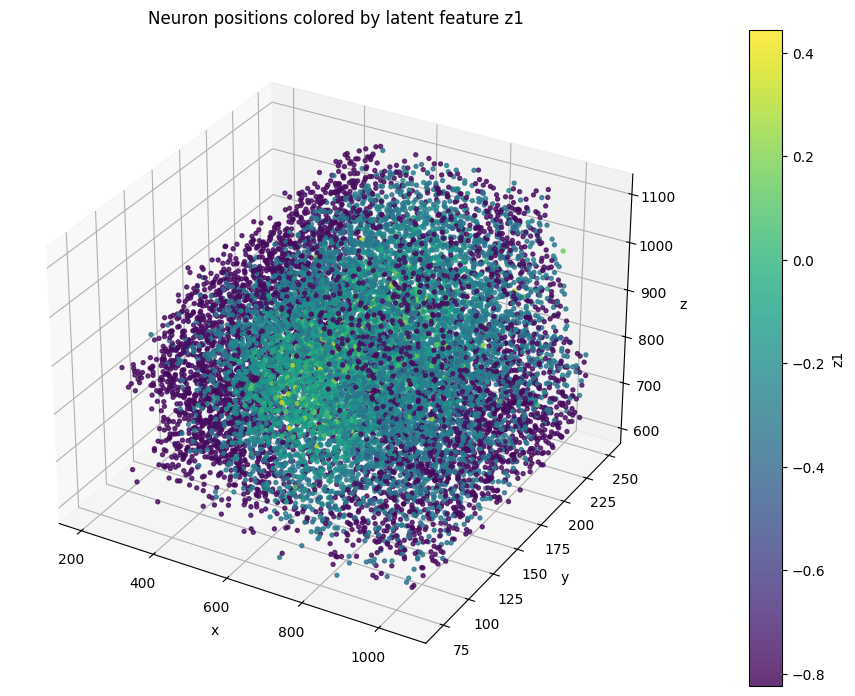

In [24]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df_plot = df_Z_full.dropna(
    subset=["pt_position_x", "pt_position_y", "pt_position_z", "z1"]
).copy()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df_plot["pt_position_x"],
    df_plot["pt_position_y"],
    df_plot["pt_position_z"],
    c=df_plot["z1"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Neuron positions colored by latent feature z1")

cbar = plt.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("z1")

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\4194641631.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


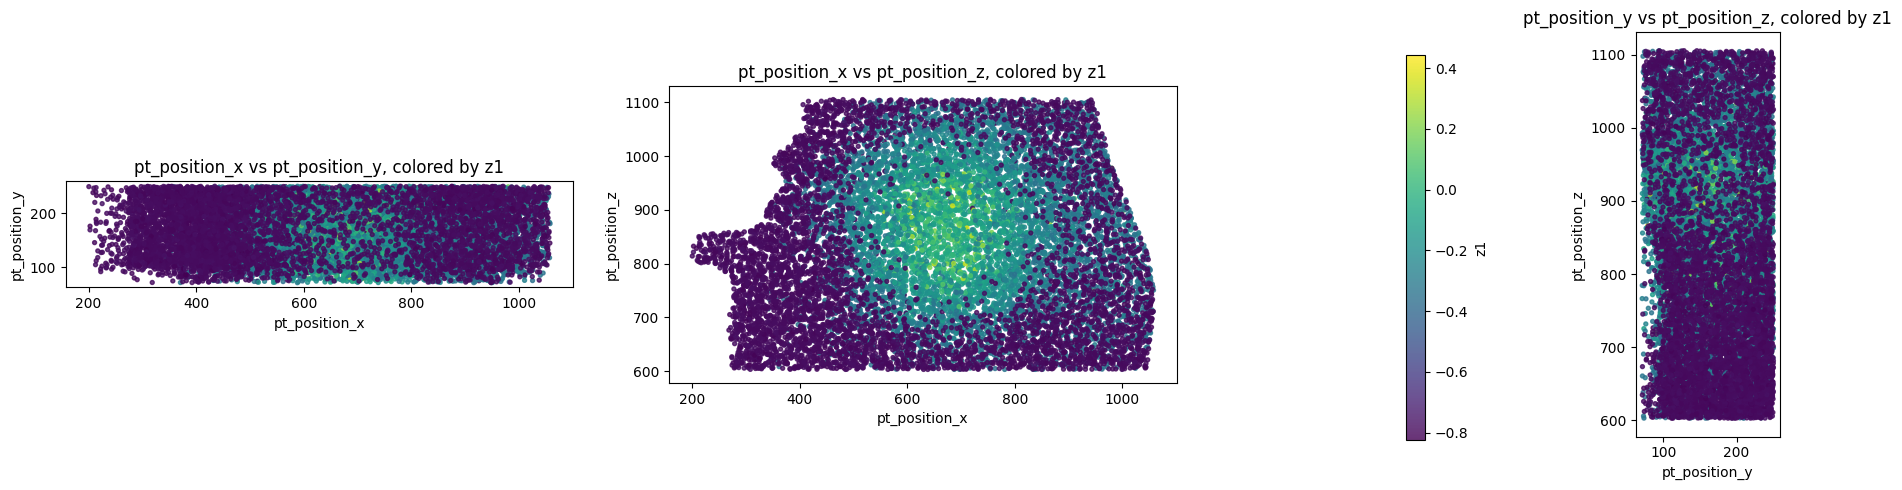

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(
        df_plot[a],
        df_plot[b],
        c=df_plot["z1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}, colored by z1")
    ax.set_aspect("equal", adjustable="box")

plt.colorbar(sc, ax=axes, label="z1")
plt.tight_layout()
plt.show()

In [26]:
for coord in ["pt_position_x", "pt_position_y", "pt_position_z"]:
    corr = df_plot["z1"].corr(df_plot[coord])
    print(f"corr(z1, {coord}) = {corr:.3f}")

corr(z1, pt_position_x) = 0.235
corr(z1, pt_position_y) = -0.074
corr(z1, pt_position_z) = 0.219


In [27]:
# ============================================================
# Distance au centre
# ============================================================

x0 = df_Z_full["pt_position_x"].mean()
y0 = df_Z_full["pt_position_y"].mean()
z0 = df_Z_full["pt_position_z"].mean()

df_Z_full["r_center"] = np.sqrt(
    (df_Z_full["pt_position_x"] - x0) ** 2 +
    (df_Z_full["pt_position_y"] - y0) ** 2 +
    (df_Z_full["pt_position_z"] - z0) ** 2
)



C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\2606175396.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("bin")


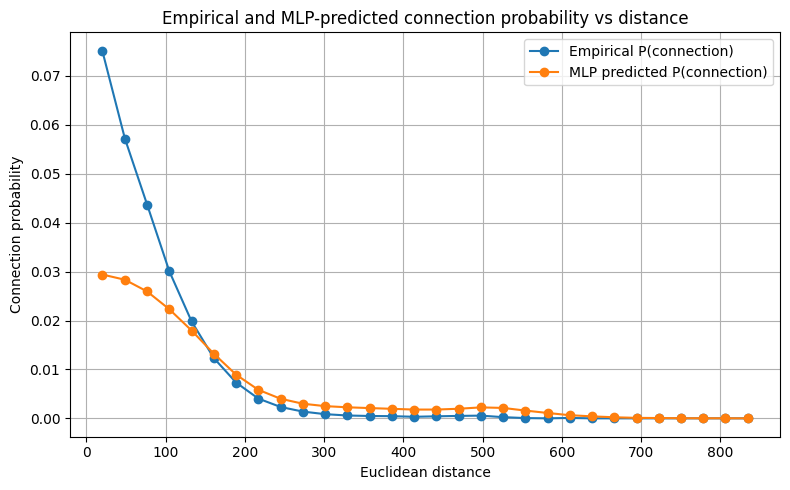

                    empirical_prob  predicted_prob  n_pairs  n_connections
bin                                                                       
(5.548, 34.458]           0.075153        0.029401    14038         1055.0
(34.458, 62.525]          0.057207        0.028335    65464         3745.0
(62.525, 90.593]          0.043692        0.025938   147053         6425.0
(90.593, 118.661]         0.030048        0.022296   245943         7390.0
(118.661, 146.728]        0.019805        0.017947   346422         6861.0


In [28]:
# ============================================================
# Empirical and MLP-predicted connection probability vs distance
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Reconstruct pair ids
# ============================================================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# ============================================================
# Get anatomical positions
# ============================================================

id_to_pos = (
    units_cleaned
    .set_index("pt_root_id")[
        ["pt_position_x", "pt_position_y", "pt_position_z"]
    ]
)

pre_pos = id_to_pos.loc[pre_ids].values
post_pos = id_to_pos.loc[post_ids].values

d_arr = np.sqrt(
    ((pre_pos - post_pos) ** 2).sum(axis=1)
)

# ============================================================
# Get model predictions
# ============================================================

model.eval()

with torch.no_grad():
    probs_pred = model(
        pre_idx.to(DEVICE),
        post_idx.to(DEVICE)
    ).detach().cpu().numpy()

y_true = y.cpu().numpy()

# ============================================================
# Build dataframe
# ============================================================

df_curve = pd.DataFrame({
    "distance": d_arr,
    "y_true": y_true,
    "p_pred": probs_pred
})

# ============================================================
# Bin by Euclidean distance
# ============================================================

n_bins = 30

df_curve["bin"] = pd.cut(
    df_curve["distance"],
    bins=n_bins
)

curve = (
    df_curve
    .groupby("bin")
    .agg(
        empirical_prob=("y_true", "mean"),
        predicted_prob=("p_pred", "mean"),
        n_pairs=("y_true", "size"),
        n_connections=("y_true", "sum")
    )
)

bin_centers = np.array([
    interval.mid
    for interval in curve.index
])

# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    bin_centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical P(connection)"
)

plt.plot(
    bin_centers,
    curve["predicted_prob"],
    marker="o",
    label="MLP predicted P(connection)"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")

plt.title(
    "Empirical and MLP-predicted connection probability vs distance"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(curve.head())

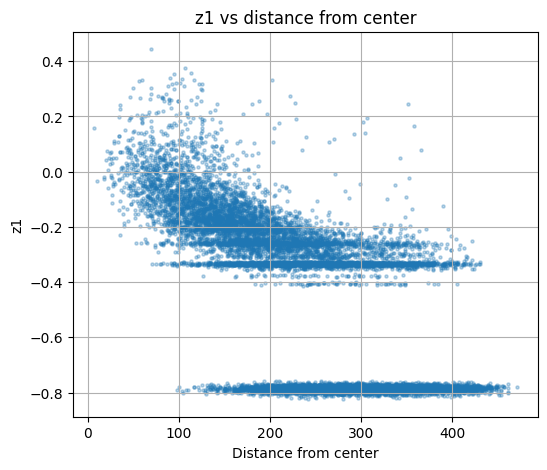

In [29]:
# ============================================================
# z1 vs distance from center
# ============================================================

plt.figure(figsize=(6, 5))

plt.scatter(
    df_Z_full["r_center"],
    df_Z_full["z1"],
    s=5,
    alpha=0.3
)

plt.xlabel("Distance from center")
plt.ylabel("z1")
plt.title("z1 vs distance from center")

plt.grid(True)
plt.show()


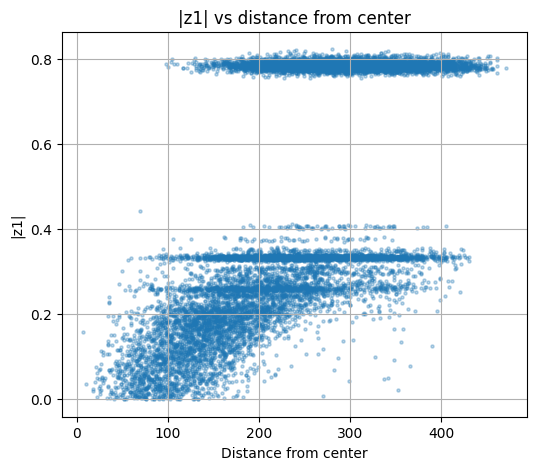

In [30]:
# ============================================================
# |z1| vs distance from center
# ============================================================

plt.figure(figsize=(6, 5))

plt.scatter(
    df_Z_full["r_center"],
    np.abs(df_Z_full["z1"]),
    s=5,
    alpha=0.3
)

plt.xlabel("Distance from center")
plt.ylabel("|z1|")
plt.title("|z1| vs distance from center")

plt.grid(True)
plt.show()

In [31]:
# ============================================================
# Degree des neurones
# ============================================================

# out-degree
out_degree = (
    synapses
    .groupby("pre_pt_root_id")
    .size()
    .rename("out_degree")
)

# in-degree
in_degree = (
    synapses
    .groupby("post_pt_root_id")
    .size()
    .rename("in_degree")
)

df_Z_full = df_Z_full.merge(
    out_degree,
    left_on="pt_root_id",
    right_index=True,
    how="left"
)

df_Z_full = df_Z_full.merge(
    in_degree,
    left_on="pt_root_id",
    right_index=True,
    how="left"
)

df_Z_full["out_degree"] = df_Z_full["out_degree"].fillna(0)
df_Z_full["in_degree"] = df_Z_full["in_degree"].fillna(0)

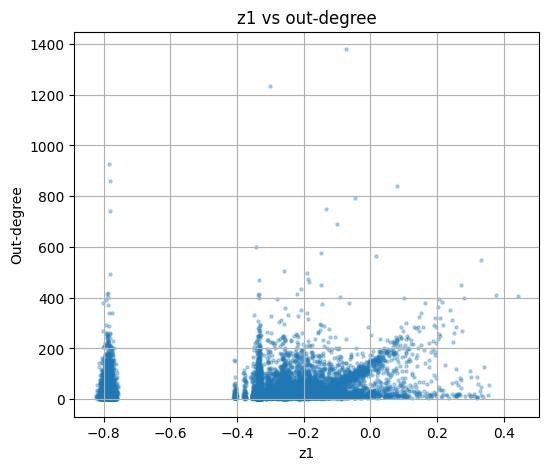

In [32]:
# ============================================================
# z1 vs out-degree
# ============================================================

plt.figure(figsize=(6, 5))

plt.scatter(
    df_Z_full["z1"],
    df_Z_full["out_degree"],
    s=5,
    alpha=0.3
)

plt.xlabel("z1")
plt.ylabel("Out-degree")
plt.title("z1 vs out-degree")

plt.grid(True)
plt.show()

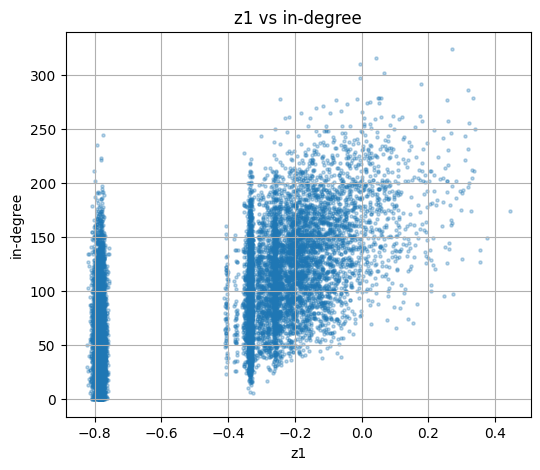

In [33]:
# ============================================================
# z1 vs in-degree
# ============================================================

plt.figure(figsize=(6, 5))

plt.scatter(
    df_Z_full["z1"],
    df_Z_full["in_degree"],
    s=5,
    alpha=0.3
)

plt.xlabel("z1")
plt.ylabel("in-degree")
plt.title("z1 vs in-degree")

plt.grid(True)
plt.show()


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\2620885248.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  prob_conn = df_pairs.groupby("bin")["connected"].mean()


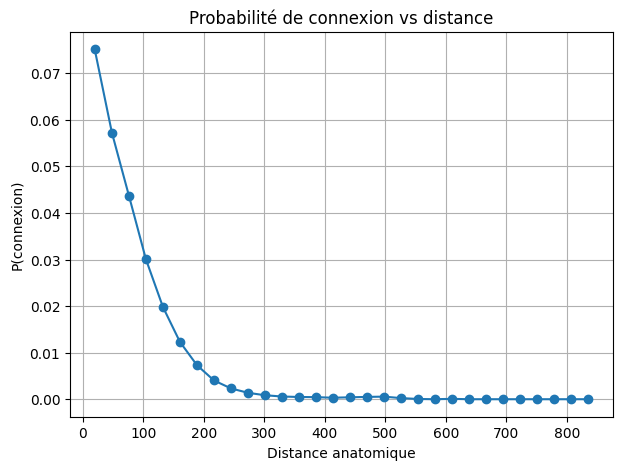

In [34]:
# ============================================================
# Courbe P(connexion | distance)
# ============================================================

# Reconstruction des distances anatomiques
d_arr = X[:, features.index("euclidean")]

df_pairs = pd.DataFrame({
    "distance": d_arr,
    "connected": y.cpu().numpy()
})

n_bins = 30

df_pairs["bin"] = pd.cut(
    df_pairs["distance"],
    bins=n_bins
)

prob_conn = df_pairs.groupby("bin")["connected"].mean()
bin_centers = np.array([
    interval.mid for interval in prob_conn.index
])

plt.figure(figsize=(7, 5))

plt.plot(
    bin_centers,
    prob_conn.values,
    marker="o"
)

plt.xlabel("Distance anatomique")
plt.ylabel("P(connexion)")
plt.title("Probabilité de connexion vs distance")

plt.grid(True)
plt.show()


In [35]:
# ============================================================
# Rebuild pair dataframe
# ============================================================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

df_pairs_full = pd.DataFrame({
    "pre_pt_root_id": pre_ids,
    "post_pt_root_id": post_ids,
    "connected": y.cpu().numpy(),
    "distance": d_arr
})

print(df_pairs_full.head())

       pre_pt_root_id     post_pt_root_id  connected    distance
0  864691134919349258  864691135118235357        1.0   96.797638
1  864691134919349258  864691135561254369        1.0  107.779556
2  864691134919349258  864691135740933739        1.0  209.727554
3  864691134941217635  864691136706310510        1.0  140.986618
4  864691134941412707  864691135639859515        1.0  149.726013


In [36]:
# ============================================================
# z1 du neurone pre/post pour chaque paire
# ============================================================

z_lookup = dict(
    zip(df_Z_full["pt_root_id"], df_Z_full["z1"])
)

# ids des paires
pre_ids = df_pairs_full["pre_pt_root_id"].values
post_ids = df_pairs_full["post_pt_root_id"].values

z_pre = np.array([z_lookup[i] for i in pre_ids])
z_post = np.array([z_lookup[i] for i in post_ids])

# score moyen de centralité
z_pair = (np.abs(z_pre) + np.abs(z_post)) / 2


In [37]:
# ============================================================
# Split central / intermédiaire / périphérie
# ============================================================

q1 = np.quantile(z_pair, 0.33)
q2 = np.quantile(z_pair, 0.66)

labels = np.zeros(len(z_pair), dtype=int)

labels[z_pair > q1] = 1
labels[z_pair > q2] = 2

group_names = [
    "central",
    "intermediate",
    "peripheral"
]


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\3167847657.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  p_conn = sub.groupby("bin")["connected"].mean()
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\3167847657.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  p_conn = sub.groupby("bin")["connected"].mean()
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\3167847657.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True 

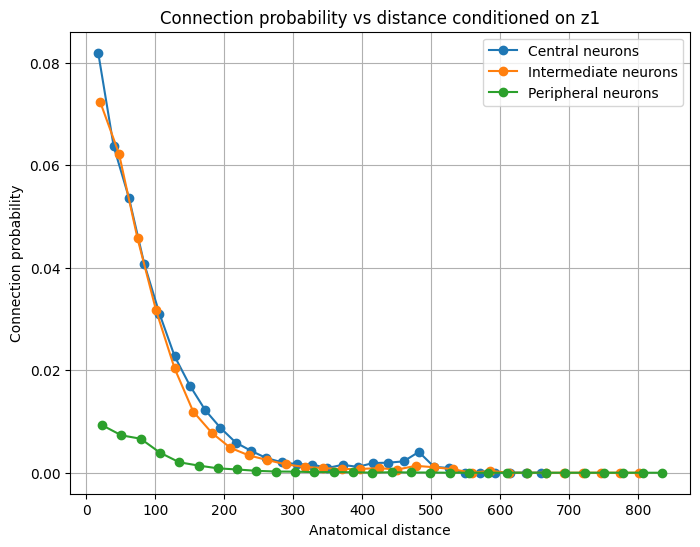

In [38]:
# ============================================================
# Connection probability vs distance conditioned on z1
# ============================================================

group_names = [
    "Central neurons",
    "Intermediate neurons",
    "Peripheral neurons"
]

plt.figure(figsize=(8, 6))

for g in range(3):

    mask = labels == g

    sub = pd.DataFrame({
        "distance": d_arr[mask],
        "connected": y.cpu().numpy()[mask]
    })

    sub["bin"] = pd.cut(
        sub["distance"],
        bins=n_bins
    )

    p_conn = sub.groupby("bin")["connected"].mean()

    centers = np.array([
        interval.mid for interval in p_conn.index
    ])

    plt.plot(
        centers,
        p_conn.values,
        marker="o",
        label=group_names[g]
    )

plt.xlabel("Anatomical distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance conditioned on z1")

plt.legend()
plt.grid(True)

plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\818604813.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  p_conn_z = df_zdist.groupby("bin")["connected"].mean()


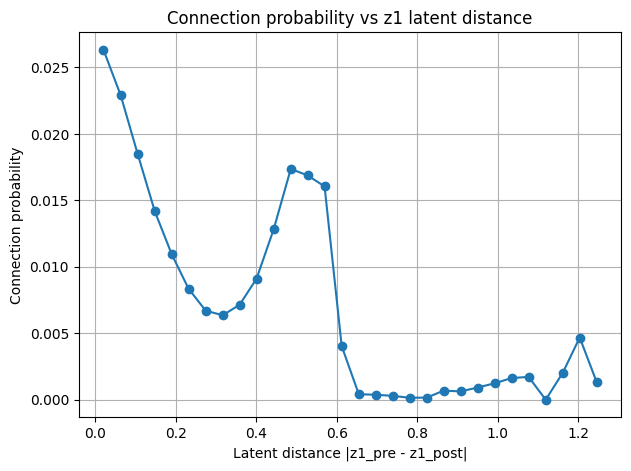

In [39]:
# ============================================================
# P(connection | z1 distance)
# ============================================================

z_lookup = dict(zip(df_Z_full["pt_root_id"], df_Z_full["z1"]))

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

z_pre = np.array([z_lookup[i] for i in pre_ids])
z_post = np.array([z_lookup[i] for i in post_ids])

z1_distance = np.abs(z_pre - z_post)

df_zdist = pd.DataFrame({
    "z1_distance": z1_distance,
    "connected": y.cpu().numpy()
})

n_bins = 30

df_zdist["bin"] = pd.cut(
    df_zdist["z1_distance"],
    bins=n_bins
)

p_conn_z = df_zdist.groupby("bin")["connected"].mean()

bin_centers_z = np.array([
    interval.mid for interval in p_conn_z.index
])

plt.figure(figsize=(7, 5))

plt.plot(
    bin_centers_z,
    p_conn_z.values,
    marker="o"
)

plt.xlabel("Latent distance |z1_pre - z1_post|")
plt.ylabel("Connection probability")
plt.title("Connection probability vs z1 latent distance")

plt.grid(True)
plt.show()

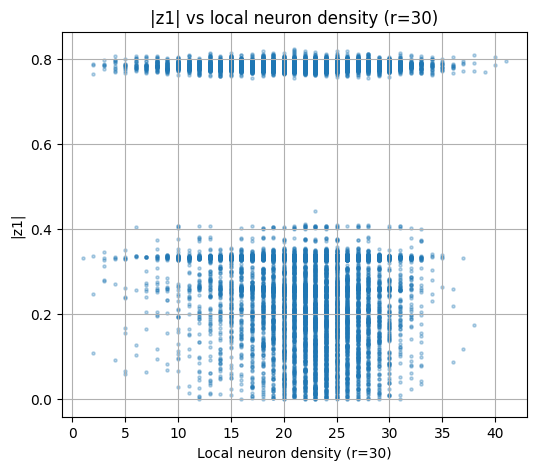

r=30 -> corr = -0.09755119944236296


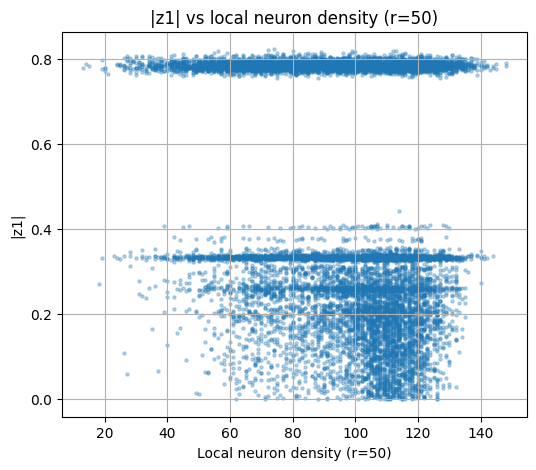

r=50 -> corr = -0.20084157089385316


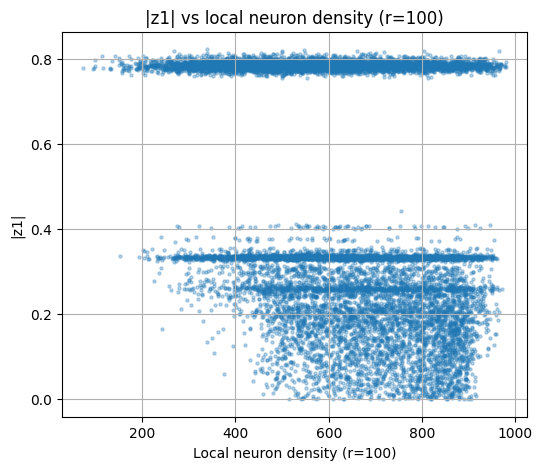

r=100 -> corr = -0.33405284214334485


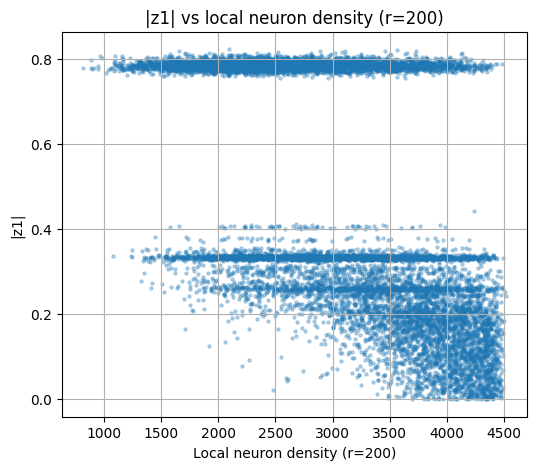

r=200 -> corr = -0.5752960762810435


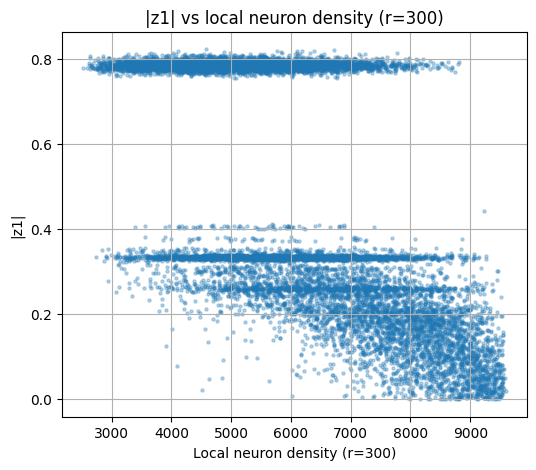

r=300 -> corr = -0.6475111763362451


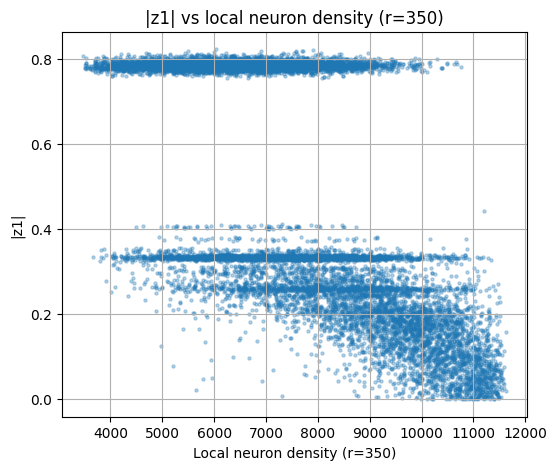

r=350 -> corr = -0.6616421355702985


In [40]:
from scipy.spatial import cKDTree
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Positions neuronales
# ============================================================

coords = df_Z_full[[
    "pt_position_x",
    "pt_position_y",
    "pt_position_z"
]].values

# ============================================================
# KDTree
# ============================================================

tree = cKDTree(coords)

# ============================================================
# Compute local density
# ============================================================

radii = [30, 50, 100, 200, 300, 350]

for r in radii:

    neighbors = tree.query_ball_point(coords, r=r)

    density = np.array([
        len(n) - 1 for n in neighbors
    ])

    df_Z_full[f"density_{r}"] = density

    # ========================================================
    # Plot z1 vs density
    # ========================================================

    plt.figure(figsize=(6,5))

    plt.scatter(
        density,
        np.abs(df_Z_full["z1"]),
        s=5,
        alpha=0.3
    )

    plt.xlabel(f"Local neuron density (r={r})")
    plt.ylabel("|z1|")

    plt.title(
        f"|z1| vs local neuron density (r={r})"
    )

    plt.grid(True)
    plt.show()

    # ========================================================
    # Correlation
    # ========================================================

    corr = np.corrcoef(
        density,
        np.abs(df_Z_full["z1"])
    )[0,1]

    print(f"r={r} -> corr =", corr)

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\1092621290.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  p_conn_euc = df_euc.groupby("bin")["connected"].mean()
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\1092621290.py:52: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  p_conn_z = df_z.groupby("bin")["connected"].mean()


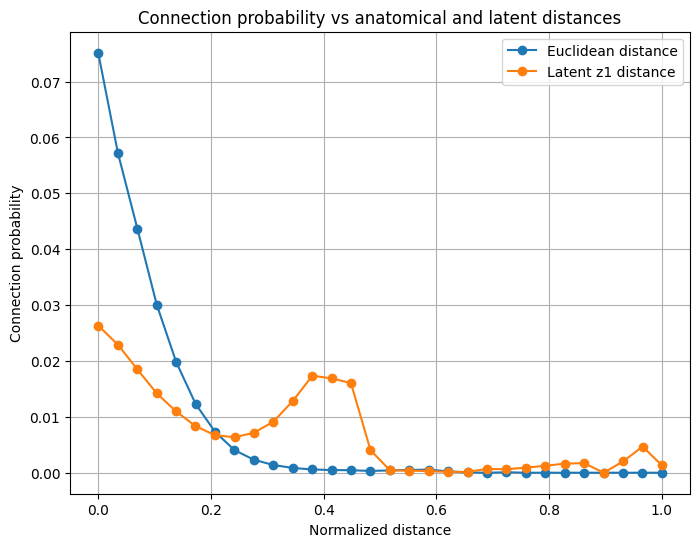

In [41]:
# ============================================================
# P(connection | anatomical distance)
# ============================================================

df_euc = pd.DataFrame({
    "distance": d_arr,
    "connected": y.cpu().numpy()
})

n_bins = 30

df_euc["bin"] = pd.cut(
    df_euc["distance"],
    bins=n_bins
)

p_conn_euc = df_euc.groupby("bin")["connected"].mean()

centers_euc = np.array([
    interval.mid for interval in p_conn_euc.index
])


# ============================================================
# P(connection | latent z1 distance)
# ============================================================

z_lookup = dict(
    zip(df_Z_full["pt_root_id"], df_Z_full["z1"])
)

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

z_pre = np.array([z_lookup[i] for i in pre_ids])
z_post = np.array([z_lookup[i] for i in post_ids])

z_dist = np.abs(z_pre - z_post)

df_z = pd.DataFrame({
    "z_dist": z_dist,
    "connected": y.cpu().numpy()
})

df_z["bin"] = pd.cut(
    df_z["z_dist"],
    bins=n_bins
)

p_conn_z = df_z.groupby("bin")["connected"].mean()

centers_z = np.array([
    interval.mid for interval in p_conn_z.index
])


# ============================================================
# Normalize x-axis for comparison
# ============================================================

x_euc = (
    centers_euc - centers_euc.min()
) / (
    centers_euc.max() - centers_euc.min()
)

x_z = (
    centers_z - centers_z.min()
) / (
    centers_z.max() - centers_z.min()
)


# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(8,6))

plt.plot(
    x_euc,
    p_conn_euc.values,
    marker="o",
    label="Euclidean distance"
)

plt.plot(
    x_z,
    p_conn_z.values,
    marker="o",
    label="Latent z1 distance"
)

plt.xlabel("Normalized distance")
plt.ylabel("Connection probability")

plt.title(
    "Connection probability vs anatomical and latent distances"
)

plt.legend()
plt.grid(True)

plt.show()

radial_group
border          4474
center          4342
intermediate    4341
Name: count, dtype: int64
                   pair_type  n_pairs  positive_rate       auc
3              center-border  1731438       0.000589  0.911051
0              border-border    80514       0.010122  0.882731
6        intermediate-border    67110       0.006333  0.862693
5        center-intermediate  1679967       0.002741  0.860529
2        border-intermediate    78138       0.005695  0.816215
8  intermediate-intermediate    65100       0.011889  0.794887
4              center-center  1679967       0.018476  0.764562
1              border-center    78156       0.002572  0.700495
7        intermediate-center    65130       0.010717  0.652081


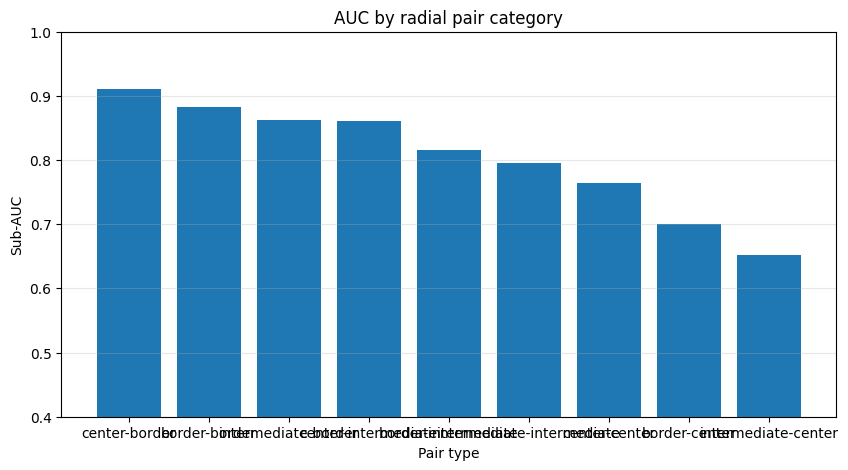

In [42]:
from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np

# ============================================================
# Radial distance relative to Y axis
# r = sqrt((x-xc)^2 + (z-zc)^2)
# ============================================================

xc = df_Z_full["pt_position_x"].mean()
zc = df_Z_full["pt_position_z"].mean()

df_Z_full["r_y_axis"] = np.sqrt(
    (df_Z_full["pt_position_x"] - xc)**2 +
    (df_Z_full["pt_position_z"] - zc)**2
)

# ============================================================
# Split neurons into 3 radial groups
# ============================================================

q1, q2 = df_Z_full["r_y_axis"].quantile([0.33, 0.66])

def radial_group(r):
    if r < q1:
        return "center"
    elif r < q2:
        return "intermediate"
    else:
        return "border"

df_Z_full["radial_group"] = df_Z_full["r_y_axis"].apply(radial_group)

print(df_Z_full["radial_group"].value_counts())


# ============================================================
# Build lookup tables
# ============================================================

group_lookup = dict(
    zip(
        df_Z_full["pt_root_id"],
        df_Z_full["radial_group"]
    )
)

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# ============================================================
# Predicted probabilities from model
# ============================================================

model.eval()

with torch.no_grad():

    probs = model(
        pre_idx,
        post_idx
    ).detach().cpu().numpy()

labels_true = y.cpu().numpy()

# ============================================================
# Pair dataframe
# ============================================================

pair_df = pd.DataFrame({
    "pre_id": pre_ids,
    "post_id": post_ids,
    "y_true": labels_true,
    "y_pred": probs
})

pair_df["pre_group"] = [
    group_lookup[i] for i in pair_df["pre_id"]
]

pair_df["post_group"] = [
    group_lookup[i] for i in pair_df["post_id"]
]

pair_df["pair_type"] = (
    pair_df["pre_group"] +
    "-" +
    pair_df["post_group"]
)

# ============================================================
# Compute sub-AUCs
# ============================================================

results_auc = []

for pair_type, sub in pair_df.groupby("pair_type"):

    n_pos = sub["y_true"].sum()
    n_neg = len(sub) - n_pos

    # AUC impossible if only one class
    if n_pos == 0 or n_neg == 0:
        continue

    auc = roc_auc_score(
        sub["y_true"],
        sub["y_pred"]
    )

    results_auc.append({
        "pair_type": pair_type,
        "n_pairs": len(sub),
        "positive_rate": sub["y_true"].mean(),
        "auc": auc
    })

results_auc = pd.DataFrame(results_auc)

# ============================================================
# Sort and display
# ============================================================

results_auc = results_auc.sort_values(
    by="auc",
    ascending=False
)

print(results_auc)

# ============================================================
# Plot
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(
    results_auc["pair_type"],
    results_auc["auc"]
)

plt.ylabel("Sub-AUC")
plt.xlabel("Pair type")
plt.title("AUC by radial pair category")

plt.ylim(0.4, 1.0)

plt.grid(axis="y", alpha=0.3)

plt.show()

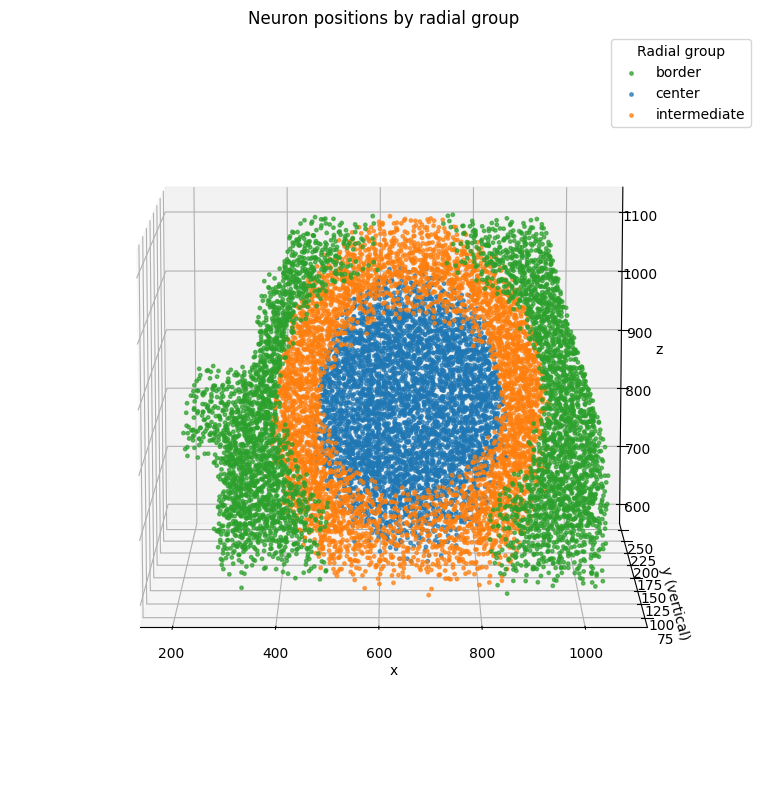

In [43]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

color_map = {
    "center": "tab:blue",
    "intermediate": "tab:orange",
    "border": "tab:green",
}

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

for group, sub in df_Z_full.groupby("radial_group"):

    ax.scatter(
        sub["pt_position_x"],   # horizontal
        sub["pt_position_y"],   # vertical
        sub["pt_position_z"],   # depth
        s=6,
        alpha=0.7,
        label=group,
        color=color_map[group]
    )

ax.set_xlabel("x")
ax.set_ylabel("y (vertical)")
ax.set_zlabel("z")

ax.set_title("Neuron positions by radial group")

ax.legend(title="Radial group")

# IMPORTANT:
# makes y visually vertical
ax.view_init(
    elev=10,
    azim=-90
)

plt.tight_layout()
plt.show()

Proofread bounding box:
x: 479.9655 1046.7697
y: 73.85182 359.2745
z: 701.96 1032.2
n proofread neurons: 972
n all neurons inside proofread volume: 12251


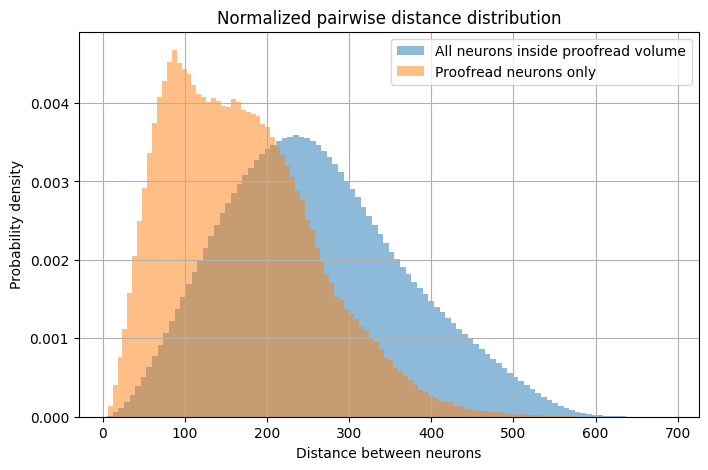

In [44]:
from scipy.spatial.distance import pdist
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Define proofread population
# ============================================================

df_proof = units_cleaned[
    units_cleaned["strategy_axon"] != "none"
].copy()

# ============================================================
# 2. Define bounding box of proofread neurons
# ============================================================

x_min, x_max = df_proof["pt_position_x"].min(), df_proof["pt_position_x"].max()
y_min, y_max = df_proof["pt_position_y"].min(), df_proof["pt_position_y"].max()
z_min, z_max = df_proof["pt_position_z"].min(), df_proof["pt_position_z"].max()

print("Proofread bounding box:")
print("x:", x_min, x_max)
print("y:", y_min, y_max)
print("z:", z_min, z_max)

# ============================================================
# 3. Keep all neurons inside proofread volume
# ============================================================

df_all_in_proof_volume = units_cleaned[
    (units_cleaned["pt_position_x"] >= x_min) &
    (units_cleaned["pt_position_x"] <= x_max) &
    (units_cleaned["pt_position_y"] >= y_min) &
    (units_cleaned["pt_position_y"] <= y_max) &
    (units_cleaned["pt_position_z"] >= z_min) &
    (units_cleaned["pt_position_z"] <= z_max)
].copy()

print("n proofread neurons:", len(df_proof))
print("n all neurons inside proofread volume:", len(df_all_in_proof_volume))

# ============================================================
# 4. Pairwise distance distribution
# ============================================================

coords_all = df_all_in_proof_volume[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
].values

coords_proof = df_proof[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
].values

dist_all = pdist(coords_all)
dist_proof = pdist(coords_proof)

# ============================================================
# 5. Plot normalized distributions
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    dist_all,
    bins=100,
    density=True,
    alpha=0.5,
    label="All neurons inside proofread volume"
)

plt.hist(
    dist_proof,
    bins=100,
    density=True,
    alpha=0.5,
    label="Proofread neurons only"
)

plt.xlabel("Distance between neurons")
plt.ylabel("Probability density")

plt.title(
    "Normalized pairwise distance distribution"
)

plt.legend()
plt.grid(True)

plt.show()



C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\2164678197.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("bin")


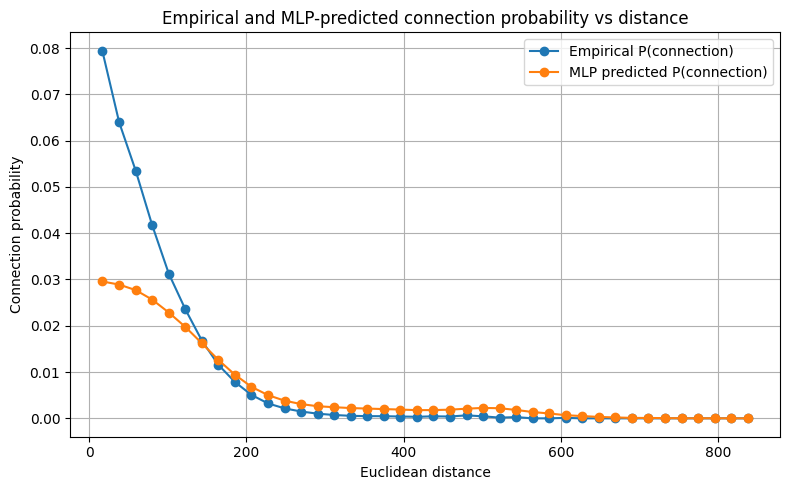

                   empirical_prob  predicted_prob  n_pairs  n_connections
bin                                                                      
(5.548, 27.441]          0.079428        0.029571     7063          561.0
(27.441, 48.492]         0.063952        0.028901    30992         1982.0
(48.492, 69.542]         0.053501        0.027704    69737         3731.0
(69.542, 90.593]         0.041688        0.025642   118763         4951.0
(90.593, 111.644]        0.031261        0.022862   174625         5459.0


In [45]:
# ============================================================
# Empirical and MLP-predicted connection probability vs distance
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Reconstruct pair ids
# ============================================================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# ============================================================
# Get anatomical positions
# ============================================================

id_to_pos = (
    units_cleaned
    .set_index("pt_root_id")[
        ["pt_position_x", "pt_position_y", "pt_position_z"]
    ]
)

pre_pos = id_to_pos.loc[pre_ids].values
post_pos = id_to_pos.loc[post_ids].values

d_arr = np.sqrt(
    ((pre_pos - post_pos) ** 2).sum(axis=1)
)

# ============================================================
# Get model predictions
# ============================================================

model.eval()

with torch.no_grad():
    probs_pred = model(
        pre_idx.to(DEVICE),
        post_idx.to(DEVICE)
    ).detach().cpu().numpy()

y_true = y.cpu().numpy()

# ============================================================
# Build dataframe
# ============================================================

df_curve = pd.DataFrame({
    "distance": d_arr,
    "y_true": y_true,
    "p_pred": probs_pred
})

# ============================================================
# Bin by Euclidean distance
# ============================================================

n_bins = 40

df_curve["bin"] = pd.cut(
    df_curve["distance"],
    bins=n_bins
)

curve = (
    df_curve
    .groupby("bin")
    .agg(
        empirical_prob=("y_true", "mean"),
        predicted_prob=("p_pred", "mean"),
        n_pairs=("y_true", "size"),
        n_connections=("y_true", "sum")
    )
)

bin_centers = np.array([
    interval.mid
    for interval in curve.index
])

# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    bin_centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical P(connection)"
)

plt.plot(
    bin_centers,
    curve["predicted_prob"],
    marker="o",
    label="MLP predicted P(connection)"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")

plt.title(
    "Empirical and MLP-predicted connection probability vs distance"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(curve.head())

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\1298439450.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\1298439450.py:181: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")



Analyzing dim = 1
Loaded best epoch: 48
Best val loss: 0.0389


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\1298439450.py:210: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\1298439450.py:181: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.539

Analyzing dim = 2
Loaded best epoch: 30
Best val loss: 0.0377


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\1298439450.py:210: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\1298439450.py:181: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = 0.396

Analyzing dim = 3
Loaded best epoch: 40
Best val loss: 0.0379
corr(geometrical distance, latent distance) = 0.389


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_88836\1298439450.py:210: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


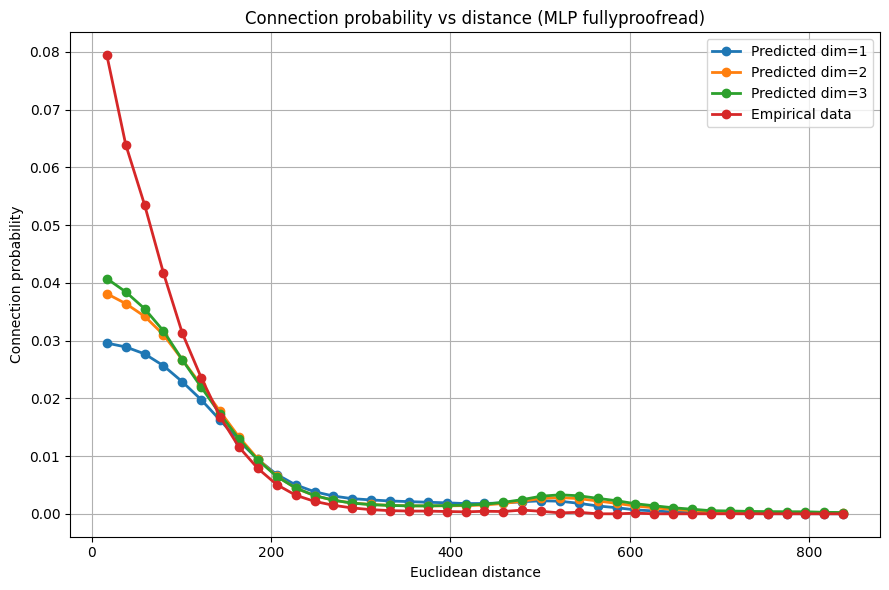

dim=3 corr=0.389


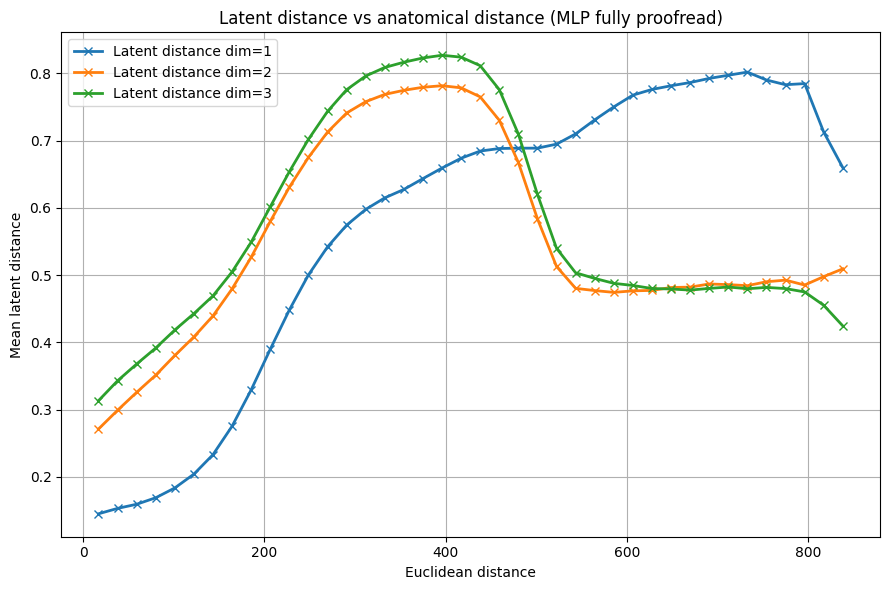

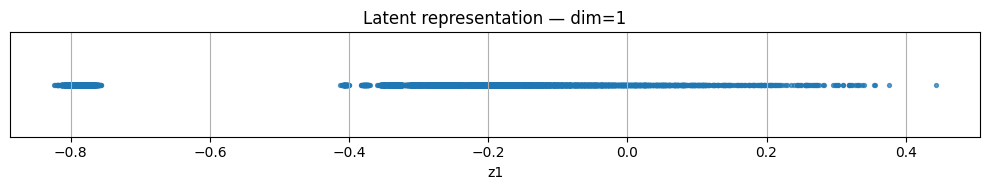

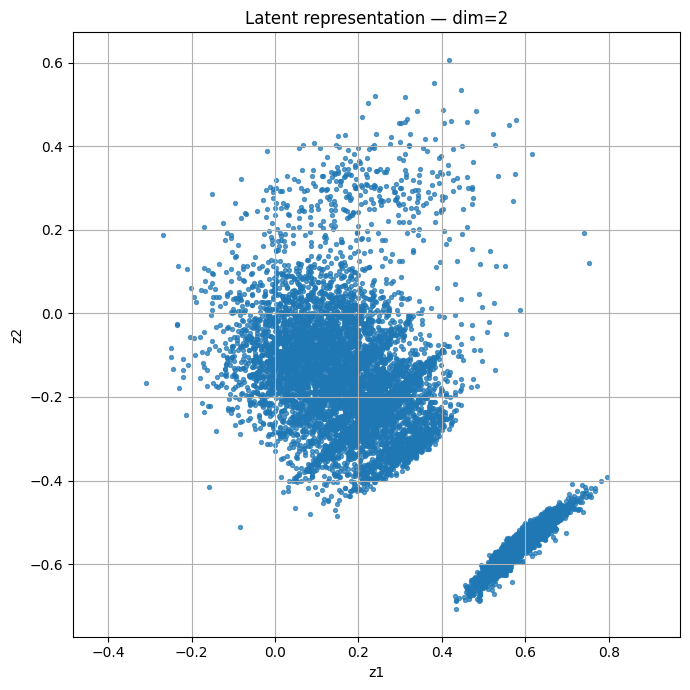

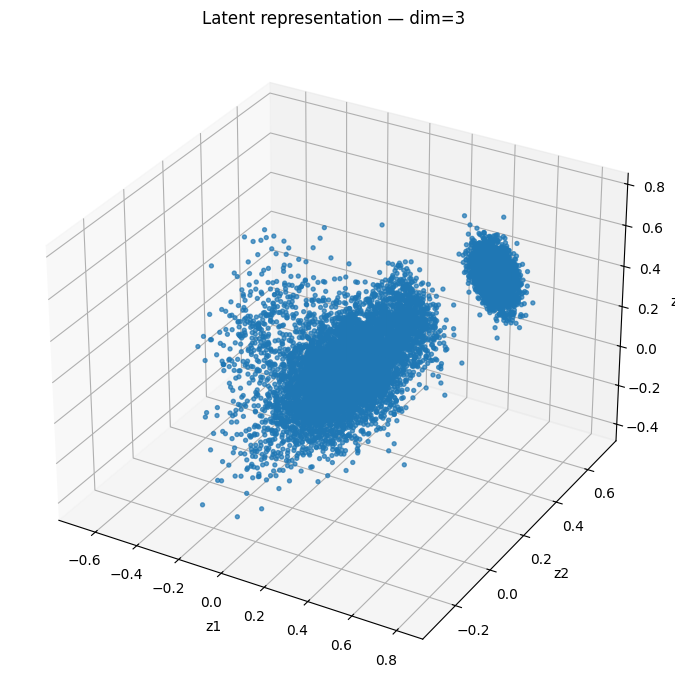

In [50]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DIMS_TO_ANALYZE = [1, 2, 3]
N_BINS = 40
BATCH_SIZE = 32768


# ============================================================
# 1. Pair ids and Euclidean distances
# ============================================================

idx_to_id = np.array(all_ids)

pre_idx_np = pre_idx.cpu().numpy() if torch.is_tensor(pre_idx) else pre_idx
post_idx_np = post_idx.cpu().numpy() if torch.is_tensor(post_idx) else post_idx

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

y_emp = y.cpu().numpy() if torch.is_tensor(y) else y


# ============================================================
# 2. Common distance bins
# ============================================================

distance_bins = np.linspace(
    distance.min(),
    distance.max(),
    N_BINS + 1
)

distance_bin = pd.cut(
    distance,
    bins=distance_bins,
    include_lowest=True
)

bin_centers = np.array([
    b.mid for b in distance_bin.categories
])


# ============================================================
# 3. Empirical curve
# ============================================================

df_emp = pd.DataFrame({
    "distance": distance,
    "y": y_emp,
    "distance_bin": distance_bin,
})

emp_curve = (
    df_emp
    .groupby("distance_bin")
    .agg(
        empirical_prob=("y", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
)


# ============================================================
# 4. Containers for all dimensions
# ============================================================

predicted_curves = {}
latent_curves = {}
latent_spaces = {}


# ============================================================
# 5. Loop over dimensions
# ============================================================

for dim in DIMS_TO_ANALYZE:

    print("\n========================")
    print(f"Analyzing dim = {dim}")
    print("========================")

    ckpt_path = os.path.join(
        CHECKPOINT_DIR,
        f"best_dim_{dim}.pt"
    )

    model = EmbeddingModel(
        n_neurons=n_neurons,
        dim=dim
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()

    print(f"Loaded best epoch: {ckpt['best_epoch']}")
    print(f"Best val loss: {ckpt['best_val_loss']:.4f}")

    # --------------------------------------------------------
    # Extract latent space
    # --------------------------------------------------------

    with torch.no_grad():
        Z = model.Z.weight.detach().cpu().numpy()

    latent_spaces[dim] = Z

    # --------------------------------------------------------
    # Predict probabilities in batches
    # --------------------------------------------------------

    all_probs = []

    with torch.no_grad():

        for start in range(0, len(y_emp), BATCH_SIZE):

            end = start + BATCH_SIZE

            pi = torch.as_tensor(
                pre_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            pj = torch.as_tensor(
                post_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            p_batch = model(
                pi,
                pj
            ).detach().cpu().numpy()

            all_probs.append(p_batch)

    p_pred = np.concatenate(all_probs)

    # --------------------------------------------------------
    # Predicted probability by anatomical distance
    # --------------------------------------------------------

    df_pred = pd.DataFrame({
        "distance": distance,
        "y": y_emp,
        "p_pred": p_pred,
        "distance_bin": distance_bin,
    })

    curve_pred = (
        df_pred
        .groupby("distance_bin")
        .agg(
            predicted_prob=("p_pred", "mean"),
            n_pairs=("p_pred", "size"),
        )
    )

    predicted_curves[dim] = curve_pred

    # --------------------------------------------------------
    # Latent distance by anatomical distance
    # --------------------------------------------------------

    z_pre = Z[pre_idx_np]
    z_post = Z[post_idx_np]

    latent_distance = np.linalg.norm(
        z_pre - z_post,
        axis=1
    )

    df_latent = pd.DataFrame({
        "geo_distance": distance,
        "latent_distance": latent_distance,
        "distance_bin": distance_bin,
    })

    curve_latent = (
        df_latent
        .groupby("distance_bin")
        .agg(
            mean_latent_distance=("latent_distance", "mean"),
            std_latent_distance=("latent_distance", "std"),
            n_pairs=("latent_distance", "size"),
        )
    )

    latent_curves[dim] = curve_latent

    corr = np.corrcoef(
        distance,
        latent_distance
    )[0, 1]

    print(
        f"corr(geometrical distance, latent distance) = {corr:.3f}"
    )


# ============================================================
# 6. Plot empirical + predicted probability for all dimensions
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        predicted_curves[dim]["predicted_prob"],
        marker="o",
        linewidth=2,
        label=f"Predicted dim={dim}"
    )

plt.plot(
    bin_centers,
    emp_curve["empirical_prob"],
    marker="o",
    linewidth=2,
    label="Empirical data"
)



plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance (MLP fullyproofread)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. Plot latent distance vs anatomical distance for all dims
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        latent_curves[dim]["mean_latent_distance"],
        marker="x",
        linewidth=2,
        label=f"Latent distance dim={dim}"
    )

    corr = np.corrcoef(
    distance,
    latent_distance
)[0,1]

print(
    f"dim={dim} "
    f"corr={corr:.3f}"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Mean latent distance")
plt.title("Latent distance vs anatomical distance (MLP fully proofread)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. Latent representation dim = 1
# ============================================================

Z1 = latent_spaces[1]

plt.figure(figsize=(10, 2))

plt.scatter(
    Z1[:, 0],
    np.zeros(len(Z1)),
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.yticks([])
plt.title("Latent representation — dim=1")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. Latent representation dim = 2
# ============================================================

Z2 = latent_spaces[2]

plt.figure(figsize=(7, 7))

plt.scatter(
    Z2[:, 0],
    Z2[:, 1],
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Latent representation — dim=2")

plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. Latent representation dim = 3
# ============================================================

Z3 = latent_spaces[3]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    Z3[:, 0],
    Z3[:, 1],
    Z3[:, 2],
    s=8,
    alpha=0.7
)

ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_zlabel("z3")
ax.set_title("Latent representation — dim=3")

plt.tight_layout()
plt.show()